### Notebook 2 — Pneumonia Cohort Definition, Experimental Splits and Scenario Design
---
>Define the binary labels (Pneumonia vs. non-Pneumonia), build leakage-free patient-level train/validation/test splits from the official ChestX-ray14 partition, quantify the availability of Pneumonia and No-Finding images, control demographic and acquisition confounders (view position, sex, age and follow-up), and prepare the nested real-data subsets (5K ⊂ 10K) that serve as the basis for the six experimental scenarios. The resulting manifests are exported for the synthetic image generation and classification notebooks.

### 1. Configuration and Loading

All design decisions that may change the experiment are centralised here:

* `POSITIVE_MODE`: `'any'` = every image whose labels contain Pneumonia (incl. comorbidities); `'pure'` = Pneumonia as the only finding.
* `MATCH_NEGATIVES`: sample No-Finding negatives so that their (view position, gender, age-bin) distribution matches the positives, reducing shortcut learning.
* Negatives for **training/validation** are `No Finding` only; the **test** set additionally keeps other-disease images as *hard negatives* (flagged, so they can be reported separately).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
DATA_PATH = '/kaggle/input/datasets/nih-chest-xrays/data'
OUT_DIR = '/kaggle/working/splits'
os.makedirs(OUT_DIR, exist_ok=True)

POSITIVE_MODE = 'any'      # 'any' | 'pure'
MATCH_NEGATIVES = True
VAL_FOLDS = 6              # 1 fold of 6  ->  ~16.7% of train_val patients go to validation
N_5K, N_10K = 5000, 10000
N_SYN_POS = 5000           # synthetic positives added in scenarios 3 and 5
MAX_IMGS_PER_PATIENT = 3   # max images per patient *per class* in train (val/test untouched)

# --- Load + same cleaning as Notebook 1 ---
df = pd.read_csv(f'{DATA_PATH}/Data_Entry_2017.csv')
df = df[df['Patient Age'] <= 120].drop(columns=['Unnamed: 11'], errors='ignore').copy()
df = df.rename(columns={'Image Index': 'image'})

# --- Label flags ---
df['is_pneumonia'] = df['Finding Labels'].str.contains('Pneumonia').astype(int)
df['is_pure_pneumonia'] = (df['Finding Labels'] == 'Pneumonia').astype(int)
df['is_no_finding'] = (df['Finding Labels'] == 'No Finding').astype(int)
df['group'] = np.select(
    [df['is_pure_pneumonia'] == 1, df['is_pneumonia'] == 1, df['is_no_finding'] == 1],
    ['Pneumonia (only)', 'Pneumonia + other', 'No Finding'],
    default='Other disease (no pneumonia)')

# --- Official patient-level split ---
def read_list(path):
    with open(path) as f:
        return set(f.read().split())

trainval_imgs = read_list(f'{DATA_PATH}/train_val_list.txt')
test_imgs = read_list(f'{DATA_PATH}/test_list.txt')
df['official_split'] = np.where(df['image'].isin(test_imgs), 'test',
                         np.where(df['image'].isin(trainval_imgs), 'train_val', 'unassigned'))

# --- Integrity checks ---
print('Images per official split:\n', df['official_split'].value_counts(), '\n')
tv_pat = set(df.loc[df.official_split == 'train_val', 'Patient ID'])
te_pat = set(df.loc[df.official_split == 'test', 'Patient ID'])
print('Patients shared between train_val and test:', len(tv_pat & te_pat), '(must be 0)')

Images per official split:
 official_split
train_val    86512
test         25592
Name: count, dtype: int64 

Patients shared between train_val and test: 0 (must be 0)


### 2. Class Availability per Official Split

How many Pneumonia images exist in each split, how many are "clean" (Pneumonia as the only finding) versus comorbid, and how many *distinct patients* they come from. Images from the same patient are highly correlated, so the number of patients is the real effective sample size.

In [2]:
counts = pd.crosstab(df['group'], df['official_split'], margins=True, margins_name='Total')
print('IMAGES per group and split:'); display(counts)

print('\nPercentage of each split:')
display((pd.crosstab(df['group'], df['official_split'], normalize='columns') * 100).round(2))

pat_counts = df.groupby(['group', 'official_split'])['Patient ID'].nunique().unstack(fill_value=0)
print('\nDISTINCT PATIENTS per group and split:'); display(pat_counts)

pn = df[df['is_pneumonia'] == 1]
print('\nPneumonia images per patient:'); print(pn.groupby('Patient ID').size().describe().round(2))

IMAGES per group and split:


official_split,test,train_val,Total
group,,,
No Finding,9861,50492,60353
Other disease (no pneumonia),15177,35144,50321
Pneumonia (only),88,234,322
Pneumonia + other,466,642,1108
Total,25592,86512,112104



Percentage of each split:


official_split,test,train_val
group,,
No Finding,38.53,58.36
Other disease (no pneumonia),59.30,40.62
Pneumonia (only),0.34,0.27
Pneumonia + other,1.82,0.74



DISTINCT PATIENTS per group and split:


official_split,test,train_val
group,,
No Finding,2557,22348
Other disease (no pneumonia),1268,12963
Pneumonia (only),69,217
Pneumonia + other,280,531



Pneumonia images per patient:
count    1008.00
mean        1.42
std         1.04
min         1.00
25%         1.00
50%         1.00
75%         1.00
max        11.00
dtype: float64


### 3. Confounder Check: View Position, Gender, Age and Follow-up

If Pneumonia and No-Finding differ systematically in acquisition (e.g. AP portable vs PA) or demographics, a classifier can learn those shortcuts instead of the disease. The same applies to generators, which may reproduce them.

View Position (% within class):


View Position,AP,PA
class,,
No Finding,34.9,65.1
Pneumonia,55.9,44.1



Gender (% within class):


Patient Gender,F,M
class,,
No Finding,43.8,56.2
Pneumonia,41.5,58.5



Age / Follow-up # by class:


class              No Finding  Pneumonia
Patient Age count     60353.0     1430.0
            mean         45.7       44.7
            std          16.5       17.6
            min           1.0        2.0
            25%          33.0       31.0
            50%          47.0       46.0
            75%          58.0       59.0
            max          95.0       90.0
Follow-up # count     60353.0     1430.0
            mean          6.1       14.4
            std          12.4       20.1
            min           0.0        0.0
            25%           0.0        2.0
            50%           2.0        7.0
            75%           6.0       18.0
            max         181.0      155.0

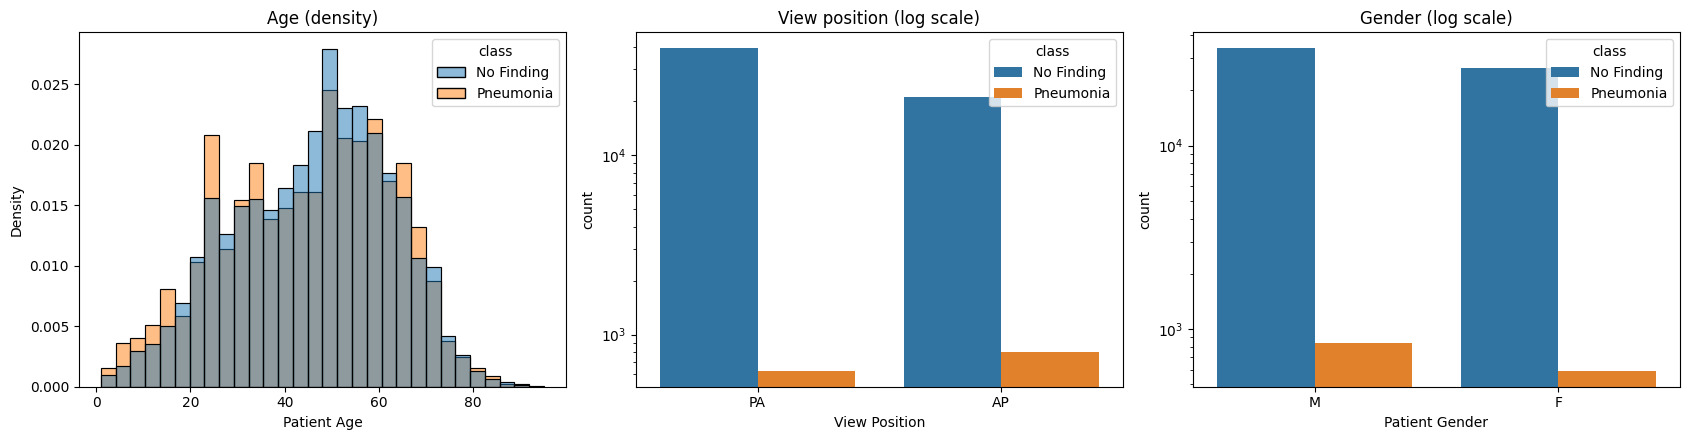

In [3]:
cmp = df[df['group'].isin(['Pneumonia (only)', 'Pneumonia + other', 'No Finding'])].copy()
cmp['class'] = np.where(cmp['is_pneumonia'] == 1, 'Pneumonia', 'No Finding')

print('View Position (% within class):')
display((pd.crosstab(cmp['class'], cmp['View Position'], normalize='index') * 100).round(1))
print('\nGender (% within class):')
display((pd.crosstab(cmp['class'], cmp['Patient Gender'], normalize='index') * 100).round(1))
print('\nAge / Follow-up # by class:')
display(cmp.groupby('class')[['Patient Age', 'Follow-up #']].describe().round(1).T)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(data=cmp, x='Patient Age', hue='class', stat='density', common_norm=False, bins=30, ax=ax[0])
ax[0].set_title('Age (density)')
sns.countplot(data=cmp, x='View Position', hue='class', ax=ax[1]); ax[1].set_yscale('log')
ax[1].set_title('View position (log scale)')
sns.countplot(data=cmp, x='Patient Gender', hue='class', ax=ax[2]); ax[2].set_yscale('log')
ax[2].set_title('Gender (log scale)')
plt.tight_layout(); plt.show()

In [4]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

meta = df[(df['official_split'] == 'train_val') &
          (df['group'].isin(['Pneumonia (only)', 'Pneumonia + other', 'No Finding']))].copy()
meta['view_AP'] = (meta['View Position'] == 'AP').astype(int)
meta['male'] = (meta['Patient Gender'] == 'M').astype(int)

feature_sets = {
    'view only':               ['view_AP'],
    'follow-up only':          ['Follow-up #'],
    'view + age + sex':        ['view_AP', 'Patient Age', 'male'],
    'view + age + sex + FU':   ['view_AP', 'Patient Age', 'male', 'Follow-up #']}

for name, cols in feature_sets.items():
    p = cross_val_predict(HistGradientBoostingClassifier(random_state=SEED),
                          meta[cols], meta['is_pneumonia'], groups=meta['Patient ID'],
                          cv=GroupKFold(n_splits=5), method='predict_proba')[:, 1]
    print(f'{name:24s} AUROC (metadata only) = {roc_auc_score(meta["is_pneumonia"], p):.3f}')

view only                AUROC (metadata only) = 0.562
follow-up only           AUROC (metadata only) = 0.640
view + age + sex         AUROC (metadata only) = 0.563
view + age + sex + FU    AUROC (metadata only) = 0.649


### 4. Binary Label Definition and Pool Construction

`label = 1` for Pneumonia (according to `POSITIVE_MODE`), `0` for non-pneumonia, `-1` for ambiguous images that are dropped (only happens in `'pure'` mode, for *Pneumonia + other*). Training/validation pools use clean negatives (`No Finding`); the test set also keeps other-disease negatives, flagged as `hard_negative`.

The table below shows what each positive definition would leave in every split, to support the choice.

In [5]:
pos_mask = (df['is_pneumonia'] == 1) if POSITIVE_MODE == 'any' else (df['is_pure_pneumonia'] == 1)
ambiguous = (df['is_pneumonia'] == 1) & ~pos_mask
df['label'] = np.where(pos_mask, 1, np.where(ambiguous, -1, 0))
df['hard_negative'] = (df['group'] == 'Other disease (no pneumonia)')

# What would each definition give us?
alt = pd.DataFrame({
    "'any' (incl. comorbid)": df[df['is_pneumonia'] == 1].groupby('official_split').size(),
    "'pure' (only Pneumonia)": df[df['is_pure_pneumonia'] == 1].groupby('official_split').size()}).fillna(0).astype(int)
print('Available positive images by definition:'); display(alt)
print(f'\nActive definition: POSITIVE_MODE = {POSITIVE_MODE!r}')

Available positive images by definition:


,'any' (incl. comorbid),'pure' (only Pneumonia)
official_split,,
test,554,88
train_val,876,234



Active definition: POSITIVE_MODE = 'any'


### 5. Patient-level Train / Validation Split

The validation set is carved out of the official `train_val` list **by patient** (`StratifiedGroupKFold`), so no patient appears in more than one of train / val / test. Validation is always real data, including for the synthetic-only scenarios.

In [6]:
# Pool of every usable train_val image (clean AND hard negatives) so patients are split once, consistently
tv_full = df[(df['official_split'] == 'train_val') & (df['label'] >= 0)].copy()

# Stratify on the 4-way 'group' (not just the binary label) so every fold keeps the same mix of
# pneumonia-only / pneumonia+other / No Finding / other-disease patients
sgkf = StratifiedGroupKFold(n_splits=VAL_FOLDS, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(tv_full, tv_full['group'], groups=tv_full['Patient ID']))

train_pool = tv_full.iloc[tr_idx]
train_pool = train_pool[~train_pool['hard_negative']].copy()      # training negatives stay clean (No Finding only)

val_full  = tv_full.iloc[va_idx].copy()                           # deployment-like (includes hard negatives)
val_clean = val_full[~val_full['hard_negative']].copy()           # Pneumonia vs No Finding

test_full  = df[(df['official_split'] == 'test') & (df['label'] >= 0)].copy()
test_clean = test_full[~test_full['hard_negative']].copy()

# --- Cap images per patient (train only, per patient and class) ---
def cap_per_patient(d, k, seed=SEED):
    d = d.sample(frac=1, random_state=seed)
    return d[d.groupby(['Patient ID', 'label']).cumcount() < k]

n_pos_before, n_neg_before = int((train_pool.label == 1).sum()), int((train_pool.label == 0).sum())
train_pool = cap_per_patient(train_pool, MAX_IMGS_PER_PATIENT).copy()
print(f'Cap of {MAX_IMGS_PER_PATIENT} images per patient and class (train only):')
print(f'  positives: {n_pos_before} -> {int((train_pool.label == 1).sum())}')
print(f'  negatives: {n_neg_before} -> {int((train_pool.label == 0).sum())}\n')

# Leakage checks
P = lambda d: set(d['Patient ID'])
sets = {'train_pool': train_pool, 'val_clean': val_clean, 'val_full': val_full,
        'test_clean': test_clean, 'test_full': test_full}
assert not (P(train_pool) & P(val_full)),  'patient leakage train/val'
assert not (P(train_pool) & P(test_full)), 'patient leakage train/test'
assert not (P(val_full)   & P(test_full)), 'patient leakage val/test'

summary = pd.DataFrame({
    name: {'images': len(d), 'positives': int((d.label == 1).sum()), 'negatives': int((d.label == 0).sum()),
           'hard_negatives': int(d['hard_negative'].sum()),
           'prevalence_%': round(100 * (d.label == 1).mean(), 2), 'patients': d['Patient ID'].nunique()}
    for name, d in sets.items()})
print('Patient-level split (no leakage):'); display(summary)

# What are the hard negatives in the test set made of? (reference for per-label specificity in Notebook 3)
hn = test_full[test_full['hard_negative']]['Finding Labels'].str.split('|').explode().value_counts()
print('\nLabels present in test hard negatives (images):'); display(hn.head(10))

Cap of 3 images per patient and class (train only):
  positives: 710 -> 683
  negatives: 41743 -> 29776

Patient-level split (no leakage):


,train_pool,val_clean,val_full,test_clean,test_full
images,30459.00,8915.00,15100.0,10415.00,25592.00
positives,683.00,166.00,166.0,554.00,554.00
negatives,29776.00,8749.00,14934.0,9861.00,25038.00
hard_negatives,0.00,0.00,6185.0,0.00,15177.00
prevalence_%,2.24,1.86,1.1,5.32,2.16
patients,18694.00,3780.00,4670.0,2576.00,2797.00



Labels present in test hard negatives (images):


Finding Labels
Infiltration          5849
Effusion              4550
Atelectasis           3197
Pneumothorax          2635
Consolidation         1755
Mass                  1713
Nodule                1596
Pleural_Thickening    1122
Emphysema             1081
Cardiomegaly          1046
Name: count, dtype: int64

### 6. Scenario Feasibility

Using the *actual* number of training positives, this table computes the composition of every scenario and the positive-class weight (`N_neg / N_pos`) that a weighted loss would need. For synthetic-only scenarios the sets are 2,500 + 2,500 by design; scenarios 3 and 5 add 5,000 synthetic positives to the same real 5K.n_pos_train = int((train_pool['label'] == 1).sum())
P5  = min(n_pos_train, N_5K // 2)
P10 = min(n_pos_train, N_10K // 2)

rows = [
    ('1. Real 5K (baseline)',       P5,              N_5K - P5),
    ('2. Synthetic only (GAN)',     2500,            2500),
    ('3. Real 5K + GAN',            P5 + N_SYN_POS,  N_5K - P5),
    ('4. Synthetic only (RoentGen)', 2500,           2500),
    ('5. Real 5K + RoentGen',       P5 + N_SYN_POS,  N_5K - P5),
    ('6. Real 10K',                 P10,             N_10K - P10)]
feas = pd.DataFrame(rows, columns=['scenario', 'n_pos', 'n_neg'])
feas['total'] = feas.n_pos + feas.n_neg
feas['pos_rate_%'] = (100 * feas.n_pos / feas.total).round(1)
feas['pos_weight (neg/pos)'] = (feas.n_neg / feas.n_pos).round(2)
print(f'Training positives available: {n_pos_train}  ->  real positives used: 5K set = {P5}, 10K set = {P10}')
display(feas)

In [7]:
n_pos_train = int((train_pool['label'] == 1).sum())
P5  = min(n_pos_train, N_5K // 2)
P10 = min(n_pos_train, N_10K // 2)

def row(kind, name, real_pos=0, real_neg=0, syn_pos=0, syn_neg=0):
    pos, neg = real_pos + syn_pos, real_neg + syn_neg
    return {'kind': kind, 'scenario': name, 'real_pos': real_pos, 'real_neg': real_neg,
            'syn_pos': syn_pos, 'syn_neg': syn_neg, 'total': pos + neg,
            'pos_rate_%': round(100 * pos / (pos + neg), 1),
            'syn_%_of_pos': round(100 * syn_pos / pos, 1), 'syn_%_of_neg': round(100 * syn_neg / neg, 1),
            'neg/pos': round(neg / pos, 2)}

rows = [row('main', '1. Real 5K (baseline)', P5, N_5K - P5),
        row('main', '6. Real 10K', P10, N_10K - P10)]
for g, (s_only, s_mix) in {'GAN': ('2', '3'), 'RoentGen': ('4', '5')}.items():
    rows.append(row('main', f'{s_only}. Synthetic only ({g})', 0, 0, 2500, 2500))
    rows.append(row('main', f'{s_mix}. Real 5K + {g} (5000 syn pos)', P5, N_5K - P5, 5000, 0))
    for n in (1000, 2500):                                   # dose-response ablation
        rows.append(row('ablation', f'{s_mix}-dose. Real 5K + {g} ({n} syn pos)', P5, N_5K - P5, n, 0))
    rows.append(row('ablation', f'{s_mix}-bal. Real 5K + {g} (5000 syn pos + 2500 syn neg)', P5, N_5K - P5, 5000, 2500))

feas = pd.DataFrame(rows).sort_values(['kind', 'scenario'], ascending=[False, True]).reset_index(drop=True)
print(f'Training positives available: {n_pos_train}  ->  real positives used: 5K set = {P5}, 10K set = {P10}')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
display(feas)

Training positives available: 683  ->  real positives used: 5K set = 683, 10K set = 683


,kind,scenario,real_pos,real_neg,syn_pos,syn_neg,total,pos_rate_%,syn_%_of_pos,syn_%_of_neg,neg/pos
0,main,1. Real 5K (baseline),683,4317,0,0,5000,13.7,0.0,0.0,6.32
1,main,2. Synthetic only (GAN),0,0,2500,2500,5000,50.0,100.0,100.0,1.00
2,main,3. Real 5K + GAN (5000 syn pos),683,4317,5000,0,10000,56.8,88.0,0.0,0.76
3,main,4. Synthetic only (RoentGen),0,0,2500,2500,5000,50.0,100.0,100.0,1.00
4,main,5. Real 5K + RoentGen (5000 syn pos),683,4317,5000,0,10000,56.8,88.0,0.0,0.76
5,main,6. Real 10K,683,9317,0,0,10000,6.8,0.0,0.0,13.64
6,ablation,3-bal. Real 5K + GAN (5000 syn pos + 2500 syn ...,683,4317,5000,2500,12500,45.5,88.0,36.7,1.20
7,ablation,3-dose. Real 5K + GAN (1000 syn pos),683,4317,1000,0,6000,28.1,59.4,0.0,2.57
8,ablation,3-dose. Real 5K + GAN (2500 syn pos),683,4317,2500,0,7500,42.4,78.5,0.0,1.36
9,ablation,5-bal. Real 5K + RoentGen (5000 syn pos + 2500...,683,4317,5000,2500,12500,45.5,88.0,36.7,1.20


### 7. Nested Real Subsets (5K ⊂ 10K)

All real positives available in `train_pool` are used (up to the cap). Negatives are drawn from the `No Finding` pool, optionally matched to the positives on *(view position, gender, age bin)*. The 10K set is sampled first and the 5K set is a random subset of it, so **5K ⊂ 10K** and scenarios 3 and 5 reuse exactly the baseline images.

In [8]:
train_pool['age_bin'] = pd.cut(train_pool['Patient Age'], [0, 18, 30, 45, 60, 75, 120])
train_pool['fu_bin'] = pd.cut(train_pool['Follow-up #'], [-1, 0, 2, 5, 10, 20, np.inf],
                              labels=['0', '1-2', '3-5', '6-10', '11-20', '>20'])

strata = lambda d: (d['View Position'].astype(str) + '_' + d['Patient Gender'].astype(str)
                    + '_' + d['age_bin'].astype(str) + '_' + d['fu_bin'].astype(str))

def matched_negative_sample(pos, pool, n, seed):
    pool = pool.assign(_k=strata(pool))
    prop = strata(pos).value_counts(normalize=True)
    picked = []
    for k, p in prop.items():
        cand = pool[pool['_k'] == k]
        picked.append(cand.sample(min(int(round(p * n)), len(cand)), random_state=seed))
    out = pd.concat(picked)
    if len(out) > n:
        out = out.sample(n, random_state=seed)
    elif len(out) < n:
        out = pd.concat([out, pool.drop(out.index).sample(n - len(out), random_state=seed)])
    return out.drop(columns='_k')

def matching_shortfall(pos, pool, n):
    need = (strata(pos).value_counts(normalize=True) * n).round().astype(int)
    have = strata(pool).value_counts().reindex(need.index).fillna(0).astype(int)
    tab = pd.DataFrame({'needed': need, 'available': have})
    tab['shortfall'] = (tab['needed'] - tab['available']).clip(lower=0)
    return tab

pos_all = train_pool[train_pool['label'] == 1].sample(frac=1, random_state=SEED)
neg_pool = train_pool[train_pool['label'] == 0]
pos_10k, pos_5k = pos_all.iloc[:P10], pos_all.iloc[:P5]

def sample_negs(pos, pool, n):
    return matched_negative_sample(pos, pool, n, SEED) if MATCH_NEGATIVES else pool.sample(n, random_state=SEED)

# 5K first: the baseline gets the best possible match; the 10K extends it (nested by construction)
n5, n_extra = N_5K - P5, (N_10K - P10) - (N_5K - P5)
sf = matching_shortfall(pos_5k, neg_pool, n5)
print(f'Strata with too few negatives (5K): {(sf.shortfall > 0).sum()} / {len(sf)} | '
      f'negatives that cannot be matched: {sf.shortfall.sum()} of {n5}')
neg_5k = sample_negs(pos_5k, neg_pool, n5)
neg_extra = sample_negs(pos_10k, neg_pool.drop(neg_5k.index), n_extra)
neg_10k = pd.concat([neg_5k, neg_extra])

real_10k = pd.concat([pos_10k, neg_10k]).sample(frac=1, random_state=SEED)
real_5k  = pd.concat([pos_5k,  neg_5k ]).sample(frac=1, random_state=SEED)

assert set(real_5k.index) <= set(real_10k.index), '5K must be nested in 10K'
assert len(real_5k) == N_5K and len(real_10k) == N_10K
print(f'real_5k : {len(real_5k)} images ({int(real_5k.label.sum())} pos / {int((real_5k.label==0).sum())} neg)')
print(f'real_10k: {len(real_10k)} images ({int(real_10k.label.sum())} pos / {int((real_10k.label==0).sum())} neg)')
print('Nested 5K ⊂ 10K: OK')

# Did the matching work?
chk = real_5k.assign(class_=np.where(real_5k.label == 1, 'Pneumonia', 'No Finding'))
print('\nReal 5K - view position (% within class):')
display((pd.crosstab(chk['class_'], chk['View Position'], normalize='index') * 100).round(1))
print('Real 5K - gender (% within class):')
display((pd.crosstab(chk['class_'], chk['Patient Gender'], normalize='index') * 100).round(1))
print('Real 5K - mean age by class:'); 
print(chk.groupby('class_')['Patient Age'].mean().round(1))
print('Real 5K - follow-up bin (% within class):')
display((pd.crosstab(chk['class_'], chk['fu_bin'], normalize='index') * 100).round(1))

Strata with too few negatives (5K): 26 / 122 | negatives that cannot be matched: 296 of 4317
real_5k : 5000 images (683 pos / 4317 neg)
real_10k: 10000 images (683 pos / 9317 neg)
Nested 5K ⊂ 10K: OK

Real 5K - view position (% within class):


View Position,AP,PA
class_,,
No Finding,39.9,60.1
Pneumonia,43.2,56.8


Real 5K - gender (% within class):


Patient Gender,F,M
class_,,
No Finding,43.0,57.0
Pneumonia,41.9,58.1


Real 5K - mean age by class:
class_
No Finding    45.5
Pneumonia     45.3
Name: Patient Age, dtype: float64
Real 5K - follow-up bin (% within class):


fu_bin,0,1-2,3-5,6-10,11-20,>20
class_,,,,,,
No Finding,21.2,24.2,20.5,15.3,13.2,5.6
Pneumonia,17.3,22.5,19.9,14.9,14.9,10.4


In [9]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

m5 = real_5k.copy()
m5['view_AP'] = (m5['View Position'] == 'AP').astype(int)
m5['male'] = (m5['Patient Gender'] == 'M').astype(int)
print('Residual metadata-only AUROC inside real_5k (0.5 = confounders removed; before matching: 0.649):')
for name, cols in {'view only': ['view_AP'], 'follow-up only': ['Follow-up #'],
                   'view+age+sex+FU': ['view_AP', 'Patient Age', 'male', 'Follow-up #']}.items():
    p = cross_val_predict(HistGradientBoostingClassifier(random_state=SEED), m5[cols], m5['label'],
                          groups=m5['Patient ID'], cv=GroupKFold(5), method='predict_proba')[:, 1]
    print(f'  {name:18s} {roc_auc_score(m5["label"], p):.3f}')

Residual metadata-only AUROC inside real_5k (0.5 = confounders removed; before matching: 0.649):
  view only          0.492
  follow-up only     0.554
  view+age+sex+FU    0.473


### 8. Statistical Power of the Evaluation Sets

With few positives in the test set, metrics such as sensitivity have wide confidence intervals. This quantifies the 95% Wilson half-width for an assumed sensitivity of 0.80, so that differences between scenarios can be interpreted honestly.

In [10]:
def wilson_halfwidth(p, n, z=1.96):
    return z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)

for name in ['val_clean', 'val_full', 'test_clean', 'test_full']:
    d = sets[name]; pos = d[d.label == 1]
    n_img, n_pat = len(pos), pos['Patient ID'].nunique()
    print(f'{name:11s}: {n_img:4d} pos images from {n_pat:4d} patients ({n_img/n_pat:.2f} img/patient) | '
          f'sens 0.80 ± {wilson_halfwidth(0.80, n_img):.3f} (by images) to ± {wilson_halfwidth(0.80, n_pat):.3f} (by patients)')
print('\nTip: use a patient-level (cluster) bootstrap for CIs and report mean ± std over several training seeds.')

val_clean  :  166 pos images from  128 patients (1.30 img/patient) | sens 0.80 ± 0.061 (by images) to ± 0.069 (by patients)
val_full   :  166 pos images from  128 patients (1.30 img/patient) | sens 0.80 ± 0.061 (by images) to ± 0.069 (by patients)
test_clean :  554 pos images from  311 patients (1.78 img/patient) | sens 0.80 ± 0.033 (by images) to ± 0.044 (by patients)
test_full  :  554 pos images from  311 patients (1.78 img/patient) | sens 0.80 ± 0.033 (by images) to ± 0.044 (by patients)

Tip: use a patient-level (cluster) bootstrap for CIs and report mean ± std over several training seeds.


### 9. Export Manifests

Builds an image-path map once (faster than searching 12 folders per image) and saves the CSV manifests used downstream:

* `real_train_pool.csv`, `real_train_positives.csv`: sources for the generators (Notebook 2). **Generators must only see training patients.**
* `real_5k.csv`, `real_10k.csv`: baseline subsets (scenarios 1, 3, 5, 6).
* `real_val.csv`, `real_test.csv`: fixed real evaluation sets shared by all scenarios.

In [11]:
path_map = {}
for folder in sorted(os.listdir(DATA_PATH)):
    d = f'{DATA_PATH}/{folder}/images'
    if folder.startswith('images_') and os.path.isdir(d):
        for f in os.listdir(d):
            path_map[f] = f'{d}/{f}'
print(f'Images located on disk: {len(path_map):,}')

cols = ['image', 'path', 'Patient ID', 'Finding Labels', 'group', 'label', 'hard_negative',
        'Patient Age', 'Patient Gender', 'View Position']
exports = {
    'real_train_pool': train_pool, 'real_train_positives': pos_all,
    'real_5k': real_5k, 'real_10k': real_10k,
    'real_val_clean': val_clean, 'real_val_full': val_full,
    'real_test_clean': test_clean, 'real_test_full': test_full}

for name, d in exports.items():
    d = d.assign(path=d['image'].map(path_map))
    missing = d['path'].isna().sum()
    d[cols].to_csv(f'{OUT_DIR}/{name}.csv', index=False)
    print(f'{name:22s} {len(d):6d} rows  | missing paths: {missing}')
print(f'\nSaved to {OUT_DIR}')

Images located on disk: 112,120
real_train_pool         30459 rows  | missing paths: 0
real_train_positives      683 rows  | missing paths: 0
real_5k                  5000 rows  | missing paths: 0
real_10k                10000 rows  | missing paths: 0
real_val_clean           8915 rows  | missing paths: 0
real_val_full           15100 rows  | missing paths: 0
real_test_clean         10415 rows  | missing paths: 0
real_test_full          25592 rows  | missing paths: 0

Saved to /kaggle/working/splits
